## Step 1: Verify the environment

**What this does:** Imports the core libraries and prints their versions.

**Why:** Confirms the notebook is using the `lingualens-env` kernel and that nothing is blocked.

**Expect:** The first run may take 1 to 3 minutes. Later runs are fast.


In [2]:
import sys, torch, transformers, shap, pandas, sklearn
print(sys.executable)
print("torch", torch.__version__, "| transformers", transformers.__version__)

c:\Users\TINA\lingualens-env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


c:\Users\TINA\lingualens-env\Scripts\python.exe
torch 2.14.0+cpu | transformers 5.18.0


In [3]:
import pandas as pd
print(pd.__version__, pd.DataFrame({"a": [1, 2]}).shape)

3.0.6 (2, 1)


## Step 2: Load the Tanglish dataset (TamilMixSentiment)

**What this does:** Downloads the Tamil-English code-mixed sentiment dataset from Hugging Face and shows its structure.

**Why:** This is the first of the three sources merged into the unified ~32K dataset. We inspect its columns and labels before cleaning.

**Expect:** A short download (the first time only), then the splits and a few sample rows.

In [4]:
from datasets import load_dataset

tamil = load_dataset("community-datasets/tamilmixsentiment")
print(tamil)
print(tamil["train"].features["label"].names)
print(tamil["train"][:3])

c:\Users\TINA\lingualens-env\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\TINA\.cache\huggingface\hub\datasets--community-datasets--tamilmixsentiment. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\TINA\lingualens-env\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `hug

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 11335
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 1260
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 3149
    })
})
['Positive', 'Negative', 'Mixed_feelings', 'unknown_state', 'not-Tamil']
{'text': ['Trailer late ah parthavanga like podunga', 'Move pathutu vanthu trailer pakurvnga yaru', 'Puthupetai dhanush  ah yarellam pathinga'], 'label': [0, 0, 0]}


## Step 2a: Trust the Windows certificate store

**What this does:** Makes Python use Windows' trusted certificates instead of its own bundled list.

**Why:** Your network or antivirus re-signs HTTPS traffic with a certificate Python doesn't know, which caused `CERTIFICATE_VERIFY_FAILED`.

**Expect:** No output. Run this before any download.


In [1]:
import truststore
truststore.inject_into_ssl()

## Step 3: Clean the Tanglish labels

**What this does:** Keeps only `Positive` and `Negative` rows, drops the three ambiguous classes, and tags each row with `language = "Tanglish"` and its original split.

**Why:** The three source datasets use incompatible label sets. We reduce each to Positive, Negative and Neutral so they can be merged into one unified dataset.

**Expect:** A table of row counts per split and label.

In [5]:
import pandas as pd

names = tamil["train"].features["label"].names
keep = {"Positive", "Negative"}

frames = []
for split in ["train", "validation", "test"]:
    df = tamil[split].to_pandas()
    df["label"] = df["label"].map(lambda i: names[i])
    df = df[df["label"].isin(keep)].copy()
    df["language"] = "Tanglish"
    df["split"] = split
    frames.append(df)

tanglish = pd.concat(frames, ignore_index=True)
print(tanglish.groupby(["split", "label"]).size())
print(len(tanglish), "rows kept")

split       label   
test        Negative     424
            Positive    2075
train       Negative    1448
            Positive    7627
validation  Negative     165
            Positive     857
dtype: int64
12596 rows kept


## Step 4: Download the Hinglish dataset (SentiMix)

**What this does:** Downloads the Hinglish training file from `RTT1/SentiMix` and prints its first lines.

**Why:** The file is in CoNLL format (one word per line), not a table. We check the layout before writing a parser.

**Expect:** About 20 lines showing a header line per tweet, then one word per line.

In [7]:
from huggingface_hub import hf_hub_download

train_path = hf_hub_download(
    repo_id="RTT1/SentiMix",
    filename="train_14k_split_conll.txt",
    repo_type="dataset",
)
with open(train_path, encoding="utf-8") as f:
    for _ in range(20):
        print(repr(f.readline()))

'meta\t4330\tneutral\n'
'nen\tEng\n'
'á\tO\n'
'vist\tEng\n'
'bolest\tEng\n'
'vztek\tEng\n'
'smutek\tEng\n'
'zmatek\tHin\n'
'osam\tHin\n'
'ě\tO\n'
'lost\tEng\n'
'beznad\tEng\n'
'ě\tO\n'
'j\tHin\n'
'a\tEng\n'
'nakonec\tEng\n'
'jen\tHin\n'
'klid\tHin\n'
'Asi\tHin\n'
'takhle\tHin\n'


c:\Users\TINA\lingualens-env\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\TINA\.cache\huggingface\hub\datasets--RTT1--SentiMix. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


## Step 5: Parse the Hinglish file into a table

**What this does:** Reads the CoNLL file, joins each tweet's tokens into one sentence, and builds a table with `text`, `label`, `language = "Hinglish"` and `split`.

**Why:** The model needs one text string and one label per row, the same shape as the Tanglish table.

**Expect:** The row count and the number of rows per label.

In [8]:
import pandas as pd

def parse_conll(path, split):
    rows, tokens, label = [], [], None
    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.rstrip("\n")
            if line.startswith("meta\t"):
                if tokens and label:
                    rows.append((" ".join(tokens), label))
                tokens, label = [], line.split("\t")[2].capitalize()
            elif line.strip():
                tokens.append(line.split("\t")[0])
        if tokens and label:
            rows.append((" ".join(tokens), label))
    df = pd.DataFrame(rows, columns=["text", "label"])
    df["language"] = "Hinglish"
    df["split"] = split
    return df

hinglish_train = parse_conll(train_path, "train")
print(len(hinglish_train), "rows")
print(hinglish_train["label"].value_counts())
print(hinglish_train.head(3))

14000 rows
label
Neutral     5264
Positive    4634
Negative    4102
Name: count, dtype: int64
                                                text     label  language  \
0  nen á vist bolest vztek smutek zmatek osam ě l...   Neutral  Hinglish   
1  @ nehantics Haan yaar neha 😔😔 kab karega woh p...   Neutral  Hinglish   
2  @ RahulGandhi television media congress ke liy...  Negative  Hinglish   

   split  
0  train  
1  train  
2  train  


## Step 6: Add the Hinglish validation split

**What this does:** Downloads `dev_3k_split_conll.txt`, parses it with the same function, and joins it to the training rows.

**Why:** Gives Hinglish a validation split like Tanglish, so evaluation uses held-out data.

**Expect:** About 3,000 validation rows and the combined row count.

In [9]:
dev_path = hf_hub_download(
    repo_id="RTT1/SentiMix",
    filename="dev_3k_split_conll.txt",
    repo_type="dataset",
)
hinglish_val = parse_conll(dev_path, "validation")
hinglish = pd.concat([hinglish_train, hinglish_val], ignore_index=True)

print(hinglish.groupby(["split", "label"]).size())
print(len(hinglish), "rows")


split       label   
train       Negative    4102
            Neutral     5264
            Positive    4634
validation  Negative     890
            Neutral     1128
            Positive     982
dtype: int64
17000 rows


## Step 7: Download DravidianCodeMix and list its files

**What this does:** Downloads the zip from GitHub into a local `data` folder, extracts it, and prints every file name.

**Why:** The zip holds Tamil, Kannada and Malayalam files. We need only Malayalam-English (Manglish), so we find those file names before loading anything.

**Expect:** A short download, then a list of file paths.

In [11]:
import requests, zipfile, io, pathlib

url = "https://github.com/bharathichezhiyan/DravidianCodeMix-Dataset/raw/main/DravidianCodeMix-2020.zip"
out = pathlib.Path("data/dravidiancodemix")
out.mkdir(parents=True, exist_ok=True)

r = requests.get(url, timeout=120)
r.raise_for_status()
with zipfile.ZipFile(io.BytesIO(r.content)) as z:
    z.extractall(out)

for p in sorted(out.rglob("*")):
    if p.is_file():
        print(p.relative_to(out))

DravidianCodeMix\kannada_offensive.csv
DravidianCodeMix\kannada_offensive_dev.csv
DravidianCodeMix\kannada_offensive_test.csv
DravidianCodeMix\kannada_offensive_train.csv
DravidianCodeMix\kannada_sentiment.csv
DravidianCodeMix\kannada_sentiment_dev.csv
DravidianCodeMix\kannada_sentiment_test.csv
DravidianCodeMix\kannada_sentiment_train.csv
DravidianCodeMix\mal_full_offensive.csv
DravidianCodeMix\mal_full_offensive_dev.csv
DravidianCodeMix\mal_full_offensive_test.csv
DravidianCodeMix\mal_full_offensive_train.csv
DravidianCodeMix\mal_full_sentiment.tsv
DravidianCodeMix\mal_full_sentiment_dev.csv
DravidianCodeMix\mal_full_sentiment_test.csv
DravidianCodeMix\mal_full_sentiment_train.csv
DravidianCodeMix\tamil_offensive_full.csv
DravidianCodeMix\tamil_offensive_full_dev.csv
DravidianCodeMix\tamil_offensive_full_test.csv
DravidianCodeMix\tamil_offensive_full_train.csv
DravidianCodeMix\tamil_sentiment_full.csv
DravidianCodeMix\tamil_sentiment_full_dev.csv
DravidianCodeMix\tamil_sentiment_full

## Step 8: Inspect the Malayalam sentiment files

**What this does:** Prints the first lines of the Malayalam train file and shows its column names.

**Why:** The separator (tab or comma) and column names aren't documented here. We check before parsing, as we did for Hinglish.

**Expect:** A few raw lines, then the column names and label counts.

In [12]:
base = out / "DravidianCodeMix"
mal_train_path = base / "mal_full_sentiment_train.csv"

with open(mal_train_path, encoding="utf-8") as f:
    for _ in range(5):
        print(repr(f.readline()))

mal = pd.read_csv(mal_train_path, sep="\t", header=None, on_bad_lines="skip")
print(mal.shape)
print(mal.head(3))
print(mal.iloc[:, -1].value_counts())


'Sathyam parayanallo trailer vijarichathra angudu kalangiyilla....nnalum all the best;Mixed_feelings;\n'
'Jayettaaaa ente chunkkeee🥰 Sabu Chettan 🥰;unknown_state;\n'
'നായകൻമാരെ കണ്ട് കഴിഞ്ഞ സ്ഥിതിക്ക് ഇനി വില്ലന്റെ ഊഴം FaFa;unknown_state;\n'
'മവനെ കൊല ഗാൻഡിൽ ഇറുക്ക് കൊല്ലാമേ വിടമാട്ടെ...;not-malayalam;\n'
'1:38 ee scene kaanaan vendi trailer kaanunnath aarokke ??;unknown_state;\n'
(15694, 1)
                                                   0
0  Sathyam parayanallo trailer vijarichathra angu...
1  Jayettaaaa ente chunkkeee🥰 Sabu Chettan 🥰;unkn...
2  നായകൻമാരെ കണ്ട് കഴിഞ്ഞ സ്ഥിതിക്ക് ഇനി വില്ലന്റ...
0
ഒരു കട്ട മമ്മൂക്ക ഫാൻ ആയ ഞാൻ മുക്കുത്തി എന്ന ഗാനം നിങ്ങൾ ഏവരെയും പോലെ തന്നെ കാത്തിരുന്ന കണ്ട ഗാനമാണ്. പിന്നാലെ കുറെ ഫാൻസുകാരുടെ കരച്ചിലും കേട്ടു .മുക്കുത്തി അവിടെ കണ്ടില്ല . ഇവിടെ എടുത്തു ,എല്ലാം പറഞ്ഞുകൊണ്ട് .. ഒരു ലോഡ് പുച്ഛം വാരിവിതറി കൊണ്ട് ഒരു കാര്യം നിങ്ങളുടെ ഓർമ്മയിലേക്ക് ധരിപ്പിക്കാൻ ആയിട്ട് ആഗ്രഹിക്കുകയാണ്. കാരണം നിങ്ങൾ എത്ര പേർ മൂക്കുത്തി എന്ന കലാരൂപത്തെക്കുറിച്ച് കേട്ടിരിക്കും 

## Step 9: Parse the Malayalam (Manglish) files

**What this does:** Reads the train, dev and test files line by line, splits each into `text` and `label` from the right, and keeps only `Positive` and `Negative`. It tags each row with `language = "Manglish"` and its split.

**Why:** Same cleaning rule as Tanglish. The ambiguous classes (`Mixed_feelings`, `unknown_state`, `not-malayalam`) are dropped so labels match across the three languages.

**Expect:** Row counts per split and label, plus a count of lines skipped because they didn't fit the format.

In [13]:
valid = {"Positive", "Negative", "Mixed_feelings", "unknown_state", "not-malayalam"}
keep = {"Positive", "Negative"}

def parse_mal(path, split):
    rows, skipped = [], 0
    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.rstrip("\n").rstrip(";")
            if ";" not in line:
                skipped += 1
                continue
            text, label = line.rsplit(";", 1)
            if label.strip() in valid:
                rows.append((text.strip(), label.strip()))
            else:
                skipped += 1
    df = pd.DataFrame(rows, columns=["text", "label"])
    print(split, "parsed:", len(df), "| skipped:", skipped)
    df = df[df["label"].isin(keep)].copy()
    df["language"] = "Manglish"
    df["split"] = split
    return df

manglish = pd.concat(
    [parse_mal(base / f"mal_full_sentiment_{s}.csv", name)
     for s, name in [("train", "train"), ("dev", "validation"), ("test", "test")]],
    ignore_index=True,
)
print(manglish.groupby(["split", "label"]).size())
print(len(manglish), "rows kept")

train parsed: 15694 | skipped: 0
validation parsed: 1960 | skipped: 0
test parsed: 1962 | skipped: 0
split       label   
test        Negative     285
            Positive     755
train       Negative    2049
            Positive    6373
validation  Negative     266
            Positive     779
dtype: int64
10507 rows kept


## Step 10: Merge the three datasets and save

**What this does:** Stacks Tanglish, Hinglish and Manglish into one table with the columns `text`, `label`, `language` and `split`, removes empty and duplicate texts, and saves it to `data/unified.csv`.

**Why:** One unified file is the input for evaluation and training. Saving it means later runs load from disk instead of downloading again.

**Expect:** Row counts before and after cleaning, then counts per language and label.

In [14]:
unified = pd.concat([tanglish, hinglish, manglish], ignore_index=True)
unified["text"] = unified["text"].astype(str).str.strip()
before = len(unified)

unified = unified[unified["text"].str.len() > 0]
unified = unified.drop_duplicates(subset=["text", "language"]).reset_index(drop=True)
print(before, "->", len(unified), "rows after cleaning")

print(unified.groupby(["language", "label"]).size().unstack(fill_value=0))
unified.to_csv("data/unified.csv", index=False, encoding="utf-8-sig")

40103 -> 39619 rows after cleaning
label     Negative  Neutral  Positive
language                             
Hinglish      4992     6392      5615
Manglish      2488        0      7666
Tanglish      2029        0     10437


In [15]:
import os
print(os.path.exists("lingualens_final"), os.listdir("lingualens_final") if os.path.exists("lingualens_final") else "")

False 


In [16]:
import os
print(os.getcwd())
print(os.path.abspath("data/unified.csv"))

c:\Users\TINA\Desktop\Lingualens
c:\Users\TINA\Desktop\Lingualens\data\unified.csv


In [ ]:
import pandas as pd
print(pd.__version__, pd.DataFrame({"a": [1, 2]}).shape)

3.0.6 (2, 1)


In [17]:
import os
print(os.path.exists("lingualens_final"), os.listdir("lingualens_final") if os.path.exists("lingualens_final") else "")

True ['config.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json', 'training_args.bin']


## Step 11: Load the trained model

**What this does:** Loads the fine-tuned XLM-RoBERTa model and its tokenizer from `lingualens_final`, prints the label mapping, and predicts one test sentence.

**Why:** Confirms the model loads on CPU and shows which number the model uses for Positive, Negative and Neutral. We need this to score the predictions correctly.

**Expect:** 10 to 30 seconds to load, the label mapping, and one prediction.

In [18]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

tok = AutoTokenizer.from_pretrained("lingualens_final")
model = AutoModelForSequenceClassification.from_pretrained("lingualens_final")
model.eval()

print(model.config.id2label)

enc = tok("Trailer late ah parthavanga like podunga", return_tensors="pt")
with torch.no_grad():
    probs = torch.softmax(model(**enc).logits, dim=-1)[0]
print(probs)

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 614.83it/s]


{0: 'negative', 1: 'neutral', 2: 'positive'}
tensor([2.0866e-02, 9.8032e-05, 9.7904e-01])


## Step 12: Predict on the validation split

**What this does:** Runs the model over every validation row in batches of 32 on the CPU and saves the predicted labels and confidence to `data/val_predictions.csv`.

**Why:** These predictions are the input for the real confusion matrix and metrics in the report.

**Expect:** About 5,000 rows. This can take 5 to 15 minutes on a CPU, with a progress bar. Don't interrupt it.

In [19]:
from tqdm import tqdm

id2label = {int(k): v.capitalize() for k, v in model.config.id2label.items()}
val = unified[unified["split"] == "validation"].reset_index(drop=True)
print(len(val), "validation rows")

preds, confs = [], []
for i in tqdm(range(0, len(val), 32)):
    batch = val["text"].iloc[i:i+32].tolist()
    enc = tok(batch, return_tensors="pt", padding=True, truncation=True, max_length=128)
    with torch.no_grad():
        p = torch.softmax(model(**enc).logits, dim=-1)
    c, idx = p.max(dim=-1)
    preds += [id2label[j] for j in idx.tolist()]
    confs += c.tolist()

val["pred"] = preds
val["confidence"] = confs
val.to_csv("data/val_predictions.csv", index=False, encoding="utf-8-sig")
print("saved")

4983 validation rows


100%|██████████| 156/156 [07:44<00:00,  2.98s/it]

saved


## Step 13: Metrics and confusion matrix

**What this does:** Compares the model's predictions with the true labels. It prints accuracy, precision, recall and F1 per class, then draws and saves the confusion matrix. It repeats the report per language.

**Why:** These are the real evaluation numbers for your report. Nothing here is estimated, and all of it comes from the saved predictions.

**Expect:** A text report and a figure saved as `data/confusion_matrix.png`.

OVERALL
              precision    recall  f1-score   support

    Negative      0.786     0.762     0.774      1296
     Neutral      0.787     0.745     0.765      1128
    Positive      0.863     0.897     0.880      2559

    accuracy                          0.827      4983
   macro avg      0.812     0.801     0.806      4983
weighted avg      0.826     0.827     0.826      4983

Hinglish
              precision    recall  f1-score   support

    Negative      0.826     0.849     0.838       890
     Neutral      0.787     0.745     0.765      1128
    Positive      0.813     0.843     0.828       982

    accuracy                          0.808      3000
   macro avg      0.809     0.812     0.810      3000
weighted avg      0.807     0.808     0.807      3000

Manglish
              precision    recall  f1-score   support

    Negative      0.767     0.745     0.756       243
     Neutral      0.000     0.000     0.000         0
    Positive      0.916     0.925     0.921      

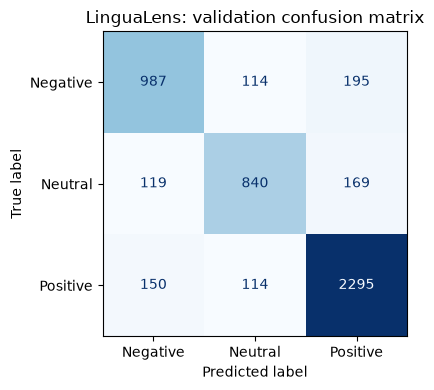

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

val = pd.read_csv("data/val_predictions.csv")
labels = ["Negative", "Neutral", "Positive"]

print("OVERALL")
print(classification_report(val["label"], val["pred"], labels=labels, digits=3, zero_division=0))

for lang, g in val.groupby("language"):
    print(lang)
    print(classification_report(g["label"], g["pred"], labels=labels, digits=3, zero_division=0))

cm = confusion_matrix(val["label"], val["pred"], labels=labels)
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("LinguaLens: validation confusion matrix")
plt.tight_layout()
plt.savefig("data/confusion_matrix.png", dpi=200)
plt.show()

### 4.x Evaluation Results

The fine-tuned XLM-RoBERTa model was evaluated on a validation set of 4,983 code-mixed comments drawn from three language pairs: Hinglish (3,000), Tanglish (1,005) and Manglish (978). Overall, the model achieved an accuracy of 82.7%, a macro-averaged F1-score of 0.806 and a weighted F1-score of 0.826. Performance was strongest on the Positive class (F1 = 0.880), followed by Negative (F1 = 0.774) and Neutral (F1 = 0.765).

Across language pairs, accuracy was 88.0% for Manglish, 83.3% for Tanglish and 80.8% for Hinglish. Hinglish was the only subset with all three classes and showed balanced performance (F1 between 0.765 and 0.838). In Manglish, Positive comments were classified reliably (F1 = 0.921) and Negative comments moderately well (F1 = 0.756). In Tanglish, Positive recall was high (0.935), but Negative recall was only 0.307 (F1 = 0.373), meaning the model missed most negative comments in this language. This weakness is consistent with the class imbalance in the source data, where Positive comments make up roughly 83% of the Tanglish examples.

Two limitations affect interpretation. First, Neutral examples come exclusively from the Hinglish source, so Neutral performance reflects Hinglish only, and macro-averaged scores for Tanglish and Manglish are not meaningful. Second, the strong Positive-class results in Tanglish and Manglish partly reflect the skewed label distribution, so accuracy alone overstates minority-class performance. These findings are examined further in the bias audit (Section 4.y).

## Step 14: Build `predict_sentiment()`

**What this does:** Loads the model once and defines a function that takes one or more texts and returns the predicted label and the probability of each class.

**Why:** The explainability step (SHAP) and the Flask API both call this function, so we write it once and reuse it.

**Expect:** About 20 seconds to load, then predictions for four test sentences in English, Hinglish, Tanglish and Manglish.

In [2]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

tok = AutoTokenizer.from_pretrained("lingualens_final")
model = AutoModelForSequenceClassification.from_pretrained("lingualens_final").eval()
id2label = {int(k): v.capitalize() for k, v in model.config.id2label.items()}

def predict_sentiment(texts):
    if isinstance(texts, str):
        texts = [texts]
    enc = tok(texts, return_tensors="pt", padding=True, truncation=True, max_length=128)
    with torch.no_grad():
        probs = torch.softmax(model(**enc).logits, dim=-1)
    results = []
    for p in probs:
        results.append({
            "label": id2label[int(p.argmax())],
            "scores": {id2label[i]: round(float(p[i]), 3) for i in range(len(p))},
        })
    return results

tests = [
    "This movie was amazing, loved it",
    "Yaar ye film bilkul bekar thi, paisa waste",
    "Trailer late ah parthavanga like podunga",
    "Ee padam kidilam, adipoli aayittund",
]
for t, r in zip(tests, predict_sentiment(tests)):
    print(r["label"], r["scores"], "|", t)

c:\Users\TINA\lingualens-env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 201/201 [00:00<00:00, 719.80it/s]


Positive {'Negative': 0.017, 'Neutral': 0.0, 'Positive': 0.983} | This movie was amazing, loved it
Negative {'Negative': 0.949, 'Neutral': 0.0, 'Positive': 0.05} | Yaar ye film bilkul bekar thi, paisa waste
Positive {'Negative': 0.021, 'Neutral': 0.0, 'Positive': 0.979} | Trailer late ah parthavanga like podunga
Positive {'Negative': 0.033, 'Neutral': 0.0, 'Positive': 0.967} | Ee padam kidilam, adipoli aayittund


## Step 15: Explain predictions with SHAP

**What this does:** Wraps `predict_sentiment` logic in a function SHAP can call, then measures how much each word pushes the prediction toward or away from a class. It runs on two sentences and prints the most influential words.

**Why:** This is the explainability feature of LinguaLens. It shows which words drove the model's decision.

**Expect:** 1 to 3 minutes on a CPU (the model is run many times with words masked), then a ranked list of words per sentence and an interactive highlight view.

In [3]:
import shap, numpy as np

def f(texts):
    texts = [str(t) for t in texts]
    enc = tok(texts, return_tensors="pt", padding=True, truncation=True, max_length=128)
    with torch.no_grad():
        return torch.softmax(model(**enc).logits, dim=-1).numpy()

names = [id2label[i] for i in range(3)]
explainer = shap.Explainer(f, shap.maskers.Text(tok), output_names=names)

samples = [tests[1], tests[2]]
sv = explainer(samples, max_evals=300)

for i, s in enumerate(samples):
    pred = int(f([s])[0].argmax())
    vals = sv.values[i][:, pred]
    toks = sv.data[i]
    order = np.argsort(-np.abs(vals))[:6]
    print(f"\n{s}\nPredicted: {names[pred]}")
    for j in order:
        print(f"  {toks[j]!r:18} {vals[j]:+.3f}")

shap.plots.text(sv)

PartitionExplainer explainer: 3it [00:21, 10.98s/it]               



Yaar ye film bilkul bekar thi, paisa waste
Predicted: Negative
  'was'              +0.386
  'te'               +0.327
  'Yaar '            -0.163
  'kul '             -0.109
  'a '               +0.075
  'pais'             +0.063

Trailer late ah parthavanga like podunga
Predicted: Positive
  'pod'              +0.062
  'late '            +0.037
  'like '            +0.032
  'ga '              +0.031
  'ah '              +0.022
  'havan'            +0.019


## Step 16: Word-level SHAP

**What this does:** Reruns SHAP with more evaluations, then adds up the sub-word pieces into whole words so the result is readable.

**Why:** Sub-word pieces like `pais` and `te` are hard to interpret. Whole words show which words drove the decision, and more evaluations give steadier values.

**Expect:** About 1 to 2 minutes, then the top words per sentence.

In [4]:
def word_attributions(sv_i, pred):
    vals = sv_i.values[:, pred]
    words, cur, cur_val = [], "", 0.0
    toks = list(sv_i.data)
    for k, (t, v) in enumerate(zip(toks, vals)):
        cur += t.strip()
        cur_val += v
        if t.endswith(" ") or k == len(toks) - 1:
            if cur:
                words.append((cur, cur_val))
            cur, cur_val = "", 0.0
    return sorted(words, key=lambda x: -abs(x[1]))

sv = explainer(samples, max_evals=1000)

for i, s in enumerate(samples):
    pred = int(f([s])[0].argmax())
    print(f"\n{s}\nPredicted: {names[pred]}")
    for w, v in word_attributions(sv[i], pred)[:6]:
        print(f"  {w:14} {v:+.3f}")


Yaar ye film bilkul bekar thi, paisa waste
Predicted: Negative
  waste          +0.713
  Yaar           -0.163
  paisa          +0.138
  bilkul         -0.128
  thi,           +0.079
  bekar          +0.068

Trailer late ah parthavanga like podunga
Predicted: Positive
  podunga        +0.064
  parthavanga    +0.041
  late           +0.037
  like           +0.032
  ah             +0.022
  Trailer        +0.009


## Step 17: Reusable explanation function

**What this does:** Packages the SHAP word-level steps into one function, `explain_text(text)`, that returns the predicted label, the class probabilities and the top words with their scores. It runs on three new sentences, one per language.

**Why:** The Flask API will call this function for the explainability panel, and it lets us test sentences with clearer sentiment words.

**Expect:** About 2 to 4 minutes for three sentences.

In [5]:
def explain_text(text, top_k=6, max_evals=600):
    pred_info = predict_sentiment(text)[0]
    pred = int(np.argmax([pred_info["scores"][n] for n in names]))
    sv_i = explainer([text], max_evals=max_evals)[0]
    words = word_attributions(sv_i, pred)[:top_k]
    return {
        "label": pred_info["label"],
        "scores": pred_info["scores"],
        "top_words": [{"word": w, "score": round(float(v), 3)} for w, v in words],
    }

more = [
    "Intha padam romba mokkai, time waste",
    "Ee cinema ishtapettilla, valare mosham",
    "Kya zabardast movie hai, dil jeet liya",
]
for t in more:
    r = explain_text(t)
    print("\n", t, "->", r["label"], r["scores"])
    for w in r["top_words"]:
        print("  ", w["word"], w["score"])


 Intha padam romba mokkai, time waste -> Negative {'Negative': 0.987, 'Neutral': 0.001, 'Positive': 0.012}
   waste 0.447
   mokkai, 0.393
   padam 0.06
   time -0.036
   Intha -0.036
   romba 0.01

 Ee cinema ishtapettilla, valare mosham -> Positive {'Negative': 0.448, 'Neutral': 0.0, 'Positive': 0.552}
   mosham -0.455
   ishtapettilla, 0.192
   valare -0.166
   cinema 0.124
   Ee -0.003

 Kya zabardast movie hai, dil jeet liya -> Positive {'Negative': 0.015, 'Neutral': 0.0, 'Positive': 0.984}
   liya -0.163
   jeet 0.148
   zabardast 0.107
   movie 0.102
   hai, -0.097
   dil 0.05


## Step 18: Probe Manglish negation

**What this does:** Runs eight short Manglish sentences, four clearly negative and four clearly positive, and prints the prediction and confidence for each.

**Why:** One wrong sentence could be chance. Eight sentences show whether the model systematically misses Malayalam negation (-illa, -illa-ya) or whether that sentence was an outlier.

**Expect:** A few seconds. No SHAP is used here.

In [6]:
probe = [
    ("Ee cinema ishtapettilla", "Negative"),
    ("Ithu oru nalla padam alla", "Negative"),
    ("Enikku ithu onnum ishtayilla, mosham", "Negative"),
    ("Climax kollilla, bore aayirunnu", "Negative"),
    ("Ee cinema ishtapettu, adipoli", "Positive"),
    ("Ithu oru nalla padam aanu", "Positive"),
    ("Enikku valare ishtayi, kidilam", "Positive"),
    ("Climax kollam, super aayirunnu", "Positive"),
]
res = predict_sentiment([t for t, _ in probe])
right = 0
for (t, true), r in zip(probe, res):
    ok = r["label"] == true
    right += ok
    print("OK " if ok else "BAD", true, "->", r["label"], r["scores"]["Negative"], "|", t)
print(right, "of", len(probe), "correct")

BAD Negative -> Positive 0.057 | Ee cinema ishtapettilla
BAD Negative -> Positive 0.268 | Ithu oru nalla padam alla
BAD Negative -> Positive 0.149 | Enikku ithu onnum ishtayilla, mosham
OK  Negative -> Negative 0.932 | Climax kollilla, bore aayirunnu
OK  Positive -> Positive 0.034 | Ee cinema ishtapettu, adipoli
OK  Positive -> Positive 0.24 | Ithu oru nalla padam aanu
OK  Positive -> Positive 0.007 | Enikku valare ishtayi, kidilam
OK  Positive -> Positive 0.117 | Climax kollam, super aayirunnu
5 of 8 correct


## Step 18b: Does negation really hurt on real Manglish data?

**What this does:** Takes the real Manglish validation rows that contain a negation ending (`illa`, `alla`, `illai`) and compares the model's accuracy on them with the accuracy on rows without one. It also prints a few misclassified examples.

**Why:** If accuracy on negation rows is clearly lower, the weakness is real and measurable, not a quirk of eight sentences.

**Expect:** A few seconds. It reads the saved `data/val_predictions.csv`.

In [7]:
import pandas as pd

val = pd.read_csv("data/val_predictions.csv")
man = val[val["language"] == "Manglish"].copy()
man["correct"] = man["label"] == man["pred"]
man["has_neg"] = man["text"].str.contains(r"\b\w*(?:illa|alla)\b", case=False, regex=True)

print(man.groupby("has_neg")["correct"].agg(["mean", "count"]).round(3))
print()
print(man.groupby(["has_neg", "label"])["correct"].agg(["mean", "count"]).round(3))

print("\nMisclassified negation rows:")
bad = man[man["has_neg"] & ~man["correct"]].head(8)
for _, r in bad.iterrows():
    print(r["label"], "->", r["pred"], "|", r["text"][:100])

          mean  count
has_neg              
False    0.886    887
True     0.824     91

                   mean  count
has_neg label                 
False   Negative  0.751    217
        Positive  0.930    670
True    Negative  0.692     26
        Positive  0.877     65

Misclassified negation rows:
Negative -> Positive | Njan oru Lalettan Fana Ennalum Enikk Teaser Ishtappettilla
Negative -> Positive | Ikkakk..valla  mass padavum cheythude....ithorumaathiri senti...cop
Negative -> Positive | ee vaga items okke kandu maduthade....oru maatavumilla.
Positive -> Negative | Sathyam paranjaal trailer kandit vella majjeyonnullalla
Negative -> Positive | veruthe oru pattu oru feeligum illa
Negative -> Positive | Ithavanekoodium hit illengil mammunni fansinte idayil nilkan kayiyilla hit kittiyillengil brithiraj 
Negative -> Positive | Trailer nte pokku kandattu valya pratheeksha illa..    nammade george ettans pole
Positive -> Negative | avasanam poomaram late aakkiyath pole late aakkuo? it

## Step 19: Save the inference code as `lingualens_core.py`

**What this does:** Writes the model loading, `predict_sentiment()` and `explain_text()` into one Python file next to the notebook.

**Why:** The Flask API and any other notebook can then run `from lingualens_core import predict_sentiment, explain_text` instead of copying code.

**Expect:** A confirmation that the file was written. SHAP loads only when `explain_text` is first called, so importing stays fast.

In [8]:
%%writefile lingualens_core.py
import os
import numpy as np
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_DIR = os.path.join(os.path.dirname(os.path.abspath(__file__)), "lingualens_final")

tok = AutoTokenizer.from_pretrained(MODEL_DIR)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_DIR).eval()
id2label = {int(k): v.capitalize() for k, v in model.config.id2label.items()}
names = [id2label[i] for i in range(len(id2label))]


def _probs(texts):
    texts = [str(t) for t in texts]
    enc = tok(texts, return_tensors="pt", padding=True, truncation=True, max_length=128)
    with torch.no_grad():
        return torch.softmax(model(**enc).logits, dim=-1)


def predict_sentiment(texts):
    if isinstance(texts, str):
        texts = [texts]
    out = []
    for p in _probs(texts):
        out.append({
            "label": id2label[int(p.argmax())],
            "scores": {id2label[i]: round(float(p[i]), 3) for i in range(len(p))},
        })
    return out


_explainer = None


def _get_explainer():
    global _explainer
    if _explainer is None:
        import shap
        f = lambda t: _probs(t).numpy()
        _explainer = shap.Explainer(f, shap.maskers.Text(tok), output_names=names)
    return _explainer


def _word_attributions(sv_i, pred):
    vals = sv_i.values[:, pred]
    toks = list(sv_i.data)
    words, cur, cur_val = [], "", 0.0
    for k, (t, v) in enumerate(zip(toks, vals)):
        cur += t.strip()
        cur_val += v
        if t.endswith(" ") or k == len(toks) - 1:
            if cur:
                words.append((cur, cur_val))
            cur, cur_val = "", 0.0
    return sorted(words, key=lambda x: -abs(x[1]))


def explain_text(text, top_k=6, max_evals=600):
    info = predict_sentiment(text)[0]
    pred = names.index(info["label"])
    sv_i = _get_explainer()([text], max_evals=max_evals)[0]
    words = _word_attributions(sv_i, pred)[:top_k]
    return {
        "label": info["label"],
        "scores": info["scores"],
        "top_words": [{"word": w, "score": round(float(v), 3)} for w, v in words],
    }

Writing lingualens_core.py


**Test the module:** imports the saved file and predicts one sentence.

In [9]:
from lingualens_core import predict_sentiment
print(predict_sentiment("Yaar ye film bilkul bekar thi, paisa waste"))

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 688.09it/s]


[{'label': 'Negative', 'scores': {'Negative': 0.949, 'Neutral': 0.0, 'Positive': 0.05}}]


## Step 20: Flask API with /predict and /explain

**What this does:** Writes `app.py`, a small web server with three routes:
- `GET /health` checks that the server is up.
- `POST /predict` takes `{"text": "..."}` and returns the label and scores (fast).
- `POST /explain` takes the same input and adds the top SHAP words (slow, a few seconds).

**Why:** This is the backend the frontend will call. It reuses `lingualens_core.py`, so the model logic lives in one place.

**Expect:** A file written here. You start the server separately in PowerShell.

In [10]:
%%writefile app.py
from flask import Flask, request, jsonify
from flask_cors import CORS
from lingualens_core import predict_sentiment, explain_text

app = Flask(__name__)
CORS(app)


def get_text():
    data = request.get_json(silent=True) or {}
    text = str(data.get("text", "")).strip()
    return text if text else None


@app.get("/health")
def health():
    return jsonify({"status": "ok"})


@app.post("/predict")
def predict():
    text = get_text()
    if not text:
        return jsonify({"error": "Send JSON like {\"text\": \"...\"}"}), 400
    return jsonify(predict_sentiment(text)[0])


@app.post("/explain")
def explain():
    text = get_text()
    if not text:
        return jsonify({"error": "Send JSON like {\"text\": \"...\"}"}), 400
    return jsonify(explain_text(text))


if __name__ == "__main__":
    app.run(host="127.0.0.1", port=5000, debug=False)

Writing app.py


## Step 21: Test the API from Python

**What this does:** Sends a request to `/predict` and `/explain` on the running server and prints the JSON response.

**Why:** Python builds the JSON correctly, so we avoid PowerShell's quoting problems. It also shows how the frontend will call the API.

**Expect:** `/predict` returns within a second. `/explain` takes 10 to 30 seconds.

In [11]:
import requests

text = "Yaar ye film bilkul bekar thi, paisa waste"

r = requests.post("http://127.0.0.1:5000/predict", json={"text": text}, timeout=60)
print("predict:", r.status_code, r.json())

r = requests.post("http://127.0.0.1:5000/explain", json={"text": text}, timeout=300)
print("explain:", r.status_code, r.json())

predict: 200 {'label': 'Negative', 'scores': {'Negative': 0.949, 'Neutral': 0.0, 'Positive': 0.05}}
explain: 200 {'label': 'Negative', 'scores': {'Negative': 0.949, 'Neutral': 0.0, 'Positive': 0.05}, 'top_words': [{'score': 0.713, 'word': 'waste'}, {'score': -0.163, 'word': 'Yaar'}, {'score': 0.138, 'word': 'paisa'}, {'score': -0.128, 'word': 'bilkul'}, {'score': 0.079, 'word': 'thi,'}, {'score': 0.068, 'word': 'bekar'}]}
